# Lab 2 – Probability, Naive Bayes and Outlier Removal

**Student:** Carlos Gutierrez – 9118309

This lab is divided into two parts:

- **Part A – Spam classification:** Where I compare Gaussian and Multinomial Naive Bayes on the email dataset, then use the better-performing model to make predictions.
- **Part B – Outlier removal:** Here I look at unusual prices in the Airbnb New York City dataset and compare a few ways of removing them.

In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # for reproducibility

---
# Part A – Spam Classification (Gaussian vs Multinomial Naive Bayes)

## A1. Load and inspect the dataset

The emails are labelled as `ham` (not spam) or `spam`. There's also an unnamed column that looks like an old index, so I drop it.

In [28]:
emails = pd.read_csv("../../practical_labs/Lab2_dataset.csv", index_col=0)
print("Shape:", emails.shape)
emails.head()

Shape: (5171, 3)


,label,text,label_num
605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
4685,spam,"Subject: photoshop , windows , office . cheap ...",1
2030,ham,Subject: re : indian springs\nthis deal is to ...,0


label
ham     3672
spam    1499
Name: count, dtype: int64

label
ham     0.71
spam    0.29
Name: proportion, dtype: float64


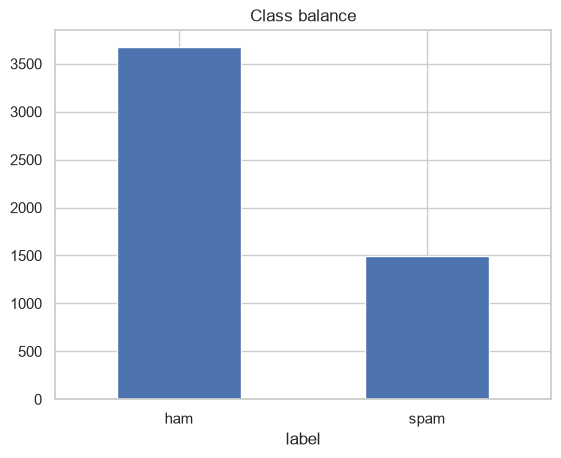

In [29]:
print(emails["label"].value_counts())
print()
print(emails["label"].value_counts(normalize=True).round(3))
emails["label"].value_counts().plot(kind="bar", title="Class balance", rot=0)
plt.show()

About 71% of the emails are ham and 29% are spam. Since the classes aren't balanced, here accuracy alone won't tell the whole story. Next I'll also check precision and recall for spam.

NOte: For the model, `label_num` is the target (0 = ham, 1 = spam), and `text` contains the email messages.

## A2. Split into train and test

Here I used an 80/20 train-test split. I also used `stratify` so the proportion of ham and spam stays about the same in both sets.

In [30]:
X_text = emails["text"]
y = emails["label_num"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train_text.shape[0], "emails | Test:", X_test_text.shape[0], "emails")

Train: 4136 emails | Test: 1035 emails


## A3. Convert the text to numbers

The models can't work with raw email text, so I used `CountVectorizer` to turn the messages into word counts.

Fitting the vectorizer only on the training data to avoid data leakage. I also limited it to 3,000 words, mainly because Gaussian NB needs a dense array, which can use quite a bit of memory. Both models get the same word-count features so that way I can compare them on equal terms.

In [31]:
vectorizer = CountVectorizer(max_features=3000, stop_words="english")
X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)
print("Feature matrix (train):", X_train.shape)

Feature matrix (train): (4136, 3000)


## A4. Train the Multinomial Naive Bayes model

I started with `MultinomialNB` because it works directly with word counts, which fits how I represented the emails.

In [32]:
mnb = MultinomialNB()
mnb.fit(X_train, y_train)
y_pred_mnb = mnb.predict(X_test)
print("Multinomial NB accuracy:", round(accuracy_score(y_test, y_pred_mnb), 4))

Multinomial NB accuracy: 0.9449


## A5. Train the Gaussian Naive Bayes model

Next is `GaussianNB`. It assumes that the features follow a normal distribution, which isn't really how word counts behave, but I wanted to see how it compares. It also needs a dense input, so I converted the sparse matrices using `.toarray()`.

In [33]:
gnb = GaussianNB()
gnb.fit(X_train.toarray(), y_train)
y_pred_gnb = gnb.predict(X_test.toarray())
print("Gaussian NB accuracy:", round(accuracy_score(y_test, y_pred_gnb), 4))

Gaussian NB accuracy: 0.9604


## A6. Evaluate both models

I compared the models using their classification reports and confusion matrices on the test set.

In [34]:
target_names = ["ham", "spam"]

for name, pred in [("Multinomial NB", y_pred_mnb), ("Gaussian NB", y_pred_gnb)]:
    print("=" * 55)
    print(name)
    print("=" * 55)
    print(classification_report(y_test, pred, target_names=target_names))

Multinomial NB
              precision    recall  f1-score   support

         ham       0.97      0.95      0.96       735
        spam       0.88      0.94      0.91       300

    accuracy                           0.94      1035
   macro avg       0.93      0.94      0.93      1035
weighted avg       0.95      0.94      0.95      1035

Gaussian NB
              precision    recall  f1-score   support

         ham       0.99      0.95      0.97       735
        spam       0.89      0.98      0.94       300

    accuracy                           0.96      1035
   macro avg       0.94      0.97      0.95      1035
weighted avg       0.96      0.96      0.96      1035



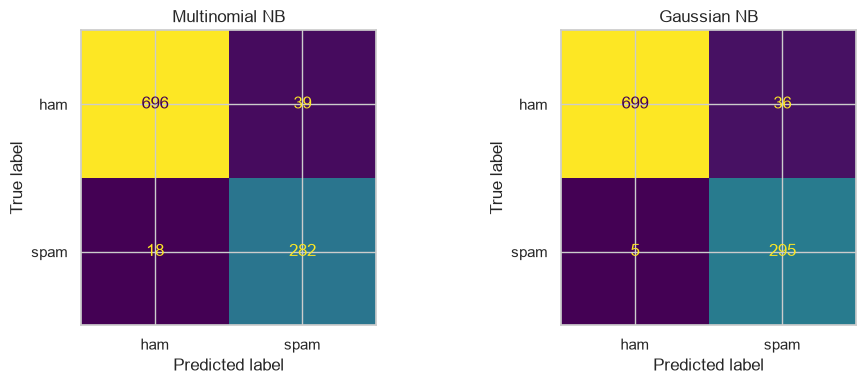

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, pred) in zip(axes, [("Multinomial NB", y_pred_mnb), ("Gaussian NB", y_pred_gnb)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=target_names).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## A7. Which model performs better?

In [36]:
report_mnb = classification_report(y_test, y_pred_mnb, output_dict=True)
report_gnb = classification_report(y_test, y_pred_gnb, output_dict=True)

comparison = pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, y_pred_mnb), accuracy_score(y_test, y_pred_gnb)],
    "Spam precision": [report_mnb["1"]["precision"], report_gnb["1"]["precision"]],
    "Spam recall": [report_mnb["1"]["recall"], report_gnb["1"]["recall"]],
    "Spam F1": [report_mnb["1"]["f1-score"], report_gnb["1"]["f1-score"]],
}, index=["Multinomial NB", "Gaussian NB"]).round(4)
comparison

,Accuracy,Spam precision,Spam recall,Spam F1
Multinomial NB,0.9449,0.8785,0.9400,0.9082
Gaussian NB,0.9604,0.8912,0.9833,0.9350


In [37]:
best_name = comparison["Accuracy"].idxmax()
print("Best model by accuracy:", best_name)


def predict_best(texts):
    """Predict labels with the best model (Gaussian NB needs a dense array)."""
    features = vectorizer.transform(texts)
    if best_name == "Gaussian NB":
        return gnb.predict(features.toarray()), gnb.predict_proba(features.toarray())[:, 1]
    return mnb.predict(features), mnb.predict_proba(features)[:, 1]

Best model by accuracy: Gaussian NB


**Conclusion:** Gaussian Naive Bayes did better on this split. It reached about **96.0% accuracy**, compared with **94.5% for Multinomial NB**. Its recall for spam was also higher (around 0.98 versus 0.94), meaning it missed fewer spam emails. Spam precision was slightly better too.

I actually expected Multinomial NB to win, since from the research I made, the inputs are word counts and that's what it is designed for. Gaussian NB assumes continuous, normally distributed features, so the result surprised me. It could be related to how certain words are distributed across spam and ham emails, but I haven't tested that explanation directly. I'd also want to try other train-test splits or vocabulary sizes before saying Gaussian NB is generally better.

## A8. Predictions on test data

Here I use the model that performed better in A7 to predict the labels of a few emails from the test set.

In [38]:
sample = X_test_text.sample(8, random_state=RANDOM_STATE)
sample_pred, _ = predict_best(sample)

predictions = pd.DataFrame({
    "text (first 80 chars)": sample.str.replace("\n", " ").str[:80].values,
    "actual": y_test.loc[sample.index].map({0: "ham", 1: "spam"}).values,
    "predicted": pd.Series(sample_pred).map({0: "ham", 1: "spam"}).values,
})
predictions

,text (first 80 chars),actual,predicted
0,Subject: account activated thank you for reply...,ham,ham
1,Subject: canvas 2005 cable t v de 5 rambler wi...,spam,spam
2,Subject: re : brandywine meter # : 981225 ; ma...,ham,ham
3,Subject: issues valero has accepted this propo...,ham,ham
4,Subject: union carbide - safety net gas union ...,ham,spam
5,Subject: re : april spot tickets the spot deal...,ham,ham
6,Subject: re : big cowboy for august mary : is ...,ham,ham
7,"Subject: enron nominations for november 8 , 20...",ham,ham


I also tried it on a few messages written specifically for this lab:

In [39]:
custom = [
    "Subject: URGENT! You have won a free prize, click here to claim your money now",
    "Subject: meeting tomorrow at 10am, please send me the gas volume report",
    "Subject: cheap meds online no prescription needed, buy now and save 80%",
    "Subject: attached are the nomination figures for next week's schedule",
]
custom_pred, custom_proba = predict_best(custom)

pd.DataFrame({
    "message": custom,
    "predicted": pd.Series(custom_pred).map({0: "ham", 1: "spam"}),
    "P(spam)": custom_proba.round(4),
})

,message,predicted,P(spam)
0,"Subject: URGENT! You have won a free prize, cl...",spam,1.0
1,"Subject: meeting tomorrow at 10am, please send...",spam,1.0
2,Subject: cheap meds online no prescription nee...,spam,1.0
3,Subject: attached are the nomination figures f...,spam,1.0


---
# Part B – Outlier Removal on Price per Night

In this part, I look at Airbnb prices in New York City. Here the idea is to remove the unusually high or low values and compare how the mean, median/MAD, IQR and percentile methods handle them.

## B1. Load and inspect the dataset

In [40]:
airbnb = pd.read_csv("../../practical_labs/AB_NYC_2019.csv")
print("Shape:", airbnb.shape)
airbnb[["name", "neighbourhood_group", "room_type", "price"]].head()

Shape: (48895, 16)


,name,neighbourhood_group,room_type,price
0,Clean & quiet apt home by the park,Brooklyn,Private room,149
1,Skylit Midtown Castle,Manhattan,Entire home/apt,225
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Private room,150
3,Cozy Entire Floor of Brownstone,Brooklyn,Entire home/apt,89
4,Entire Apt: Spacious Studio/Loft by central park,Manhattan,Entire home/apt,80


In [41]:
airbnb["price"].describe().round(2)

count    48895.00
mean       152.72
std        240.15
min          0.00
25%         69.00
50%        106.00
75%        175.00
max      10000.00
Name: price, dtype: float64

The average price is around $153, while the median is only $106. There's also a listing priced at $10,000 per night. That difference suggests the data is strongly skewed to the right, saying we have a few very high prices pulling up the mean.

## B2. Visualize the raw price distribution

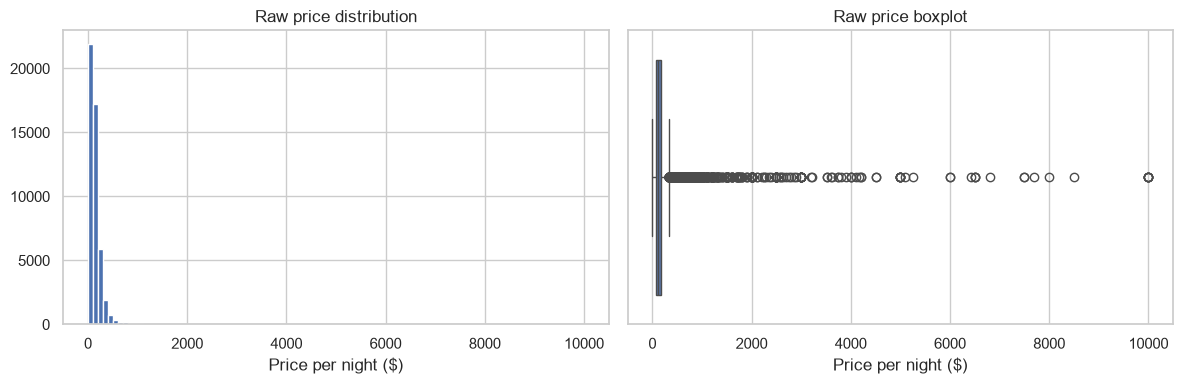

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(airbnb["price"], bins=100)
axes[0].set_title("Raw price distribution")
axes[0].set_xlabel("Price per night ($)")
sns.boxplot(x=airbnb["price"], ax=axes[1])
axes[1].set_title("Raw price boxplot")
axes[1].set_xlabel("Price per night ($)")
plt.tight_layout()
plt.show()

Most listings are grouped toward the left side of the plot, but a few expensive ones stretch the price axis all the way to $10,000. This makes the main part of the distribution hard to see.

## B3. Handle invalid prices

Some listings have a price of $0. Since that isn't a valid nightly price for this analysis, I choose to remove those rows before checking for outliers.

In [43]:
print("Listings with price = 0:", (airbnb["price"] == 0).sum())
prices_df = airbnb[airbnb["price"] > 0].copy()
print("Rows after removing price = 0:", len(prices_df))
price = prices_df["price"]

Listings with price = 0: 11
Rows after removing price = 0: 48884


## B4. Outlier detection techniques

I'll try four methods. Each one sets a range of prices to keep, but they don't all give the same limits.

### B4.1 Mean ± 3 standard deviations (z-score)

The rule here is `|price - mean| <= 3 * std`. This makes sense for data that is roughly normal. With these prices, though, the extreme values push both the mean and standard deviation up, so the range becomes pretty wide.

In [44]:
mean, std = price.mean(), price.std()
z_low, z_high = mean - 3 * std, mean + 3 * std
mask_z = (price >= z_low) & (price <= z_high)
print(f"mean = {mean:.2f}, std = {std:.2f}")
print(f"limits: [{z_low:.2f}, {z_high:.2f}]  -> removed {(~mask_z).sum()} rows")

mean = 152.76, std = 240.17
limits: [-567.76, 873.27]  -> removed 388 rows


The lower limit even ends up negative, this doesn't make sense for nightly prices. The upper limit is also high enough that this method keeps some of the really expensive listings.

### B4.2 Median and MAD (modified z-score)

For this method, `modified z = 0.6745 * (price - median) / MAD`, where MAD means *median absolute deviation*. Prices with `|modified z| > 3.5` are treated as outliers.

I wanted to try this because the median and MAD are less sensitive to extreme prices than the mean and standard deviation.

In [45]:
median = price.median()
mad = (price - median).abs().median()
mod_z = 0.6745 * (price - median) / mad
mask_mad = mod_z.abs() <= 3.5
mad_low, mad_high = median - 3.5 * mad / 0.6745, median + 3.5 * mad / 0.6745
print(f"median = {median:.2f}, MAD = {mad:.2f}")
print(f"limits: [{mad_low:.2f}, {mad_high:.2f}]  -> removed {(~mask_mad).sum()} rows")

median = 106.00, MAD = 46.00
limits: [-132.70, 344.70]  -> removed 2916 rows


### B4.3 IQR fences

The IQR method keeps prices between `Q1 - 1.5 * IQR` and `Q3 + 1.5 * IQR`, where `IQR = Q3 - Q1`. Since it uses quartiles instead of the mean, a few very expensive listings don't shift the limits as much.

In [46]:
q1, q3 = price.quantile(0.25), price.quantile(0.75)
iqr = q3 - q1
iqr_low, iqr_high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
mask_iqr = (price >= iqr_low) & (price <= iqr_high)
print(f"Q1 = {q1:.0f}, Q3 = {q3:.0f}, IQR = {iqr:.0f}")
print(f"limits: [{iqr_low:.2f}, {iqr_high:.2f}]  -> removed {(~mask_iqr).sum()} rows")

Q1 = 69, Q3 = 175, IQR = 106
limits: [-90.00, 334.00]  -> removed 2972 rows


### B4.4 Percentile cut-off

This one is straightforward: keep prices between the 1st and 99th percentiles. The downside is that it removes roughly 2% of the data by design, even if some of those prices aren't actually unusual.

In [47]:
p_low, p_high = price.quantile(0.01), price.quantile(0.99)
mask_pct = (price >= p_low) & (price <= p_high)
print(f"limits: [{p_low:.2f}, {p_high:.2f}]  -> removed {(~mask_pct).sum()} rows")

limits: [30.00, 799.00]  -> removed 867 rows


## B5. Comparison of the techniques

In [48]:
methods = {
    "Mean ± 3 std": (z_low, z_high, mask_z),
    "Median / MAD (3.5)": (mad_low, mad_high, mask_mad),
    "IQR fences (1.5)": (iqr_low, iqr_high, mask_iqr),
    "Percentiles (1%-99%)": (p_low, p_high, mask_pct),
}

summary = pd.DataFrame({
    name: {
        "Lower limit": low,
        "Upper limit": high,
        "Rows removed": int((~mask).sum()),
        "Rows kept": int(mask.sum()),
        "% removed": round((~mask).mean() * 100, 2),
        "Max price kept": price[mask].max(),
    }
    for name, (low, high, mask) in methods.items()
}).T.round(2)
summary

,Lower limit,Upper limit,Rows removed,Rows kept,% removed,Max price kept
Mean ± 3 std,-567.76,873.27,388.0,48496.0,0.79,860.0
Median / MAD (3.5),-132.70,344.70,2916.0,45968.0,5.97,344.0
IQR fences (1.5),-90.00,334.00,2972.0,45912.0,6.08,334.0
Percentiles (1%-99%),30.00,799.00,867.0,48017.0,1.77,799.0


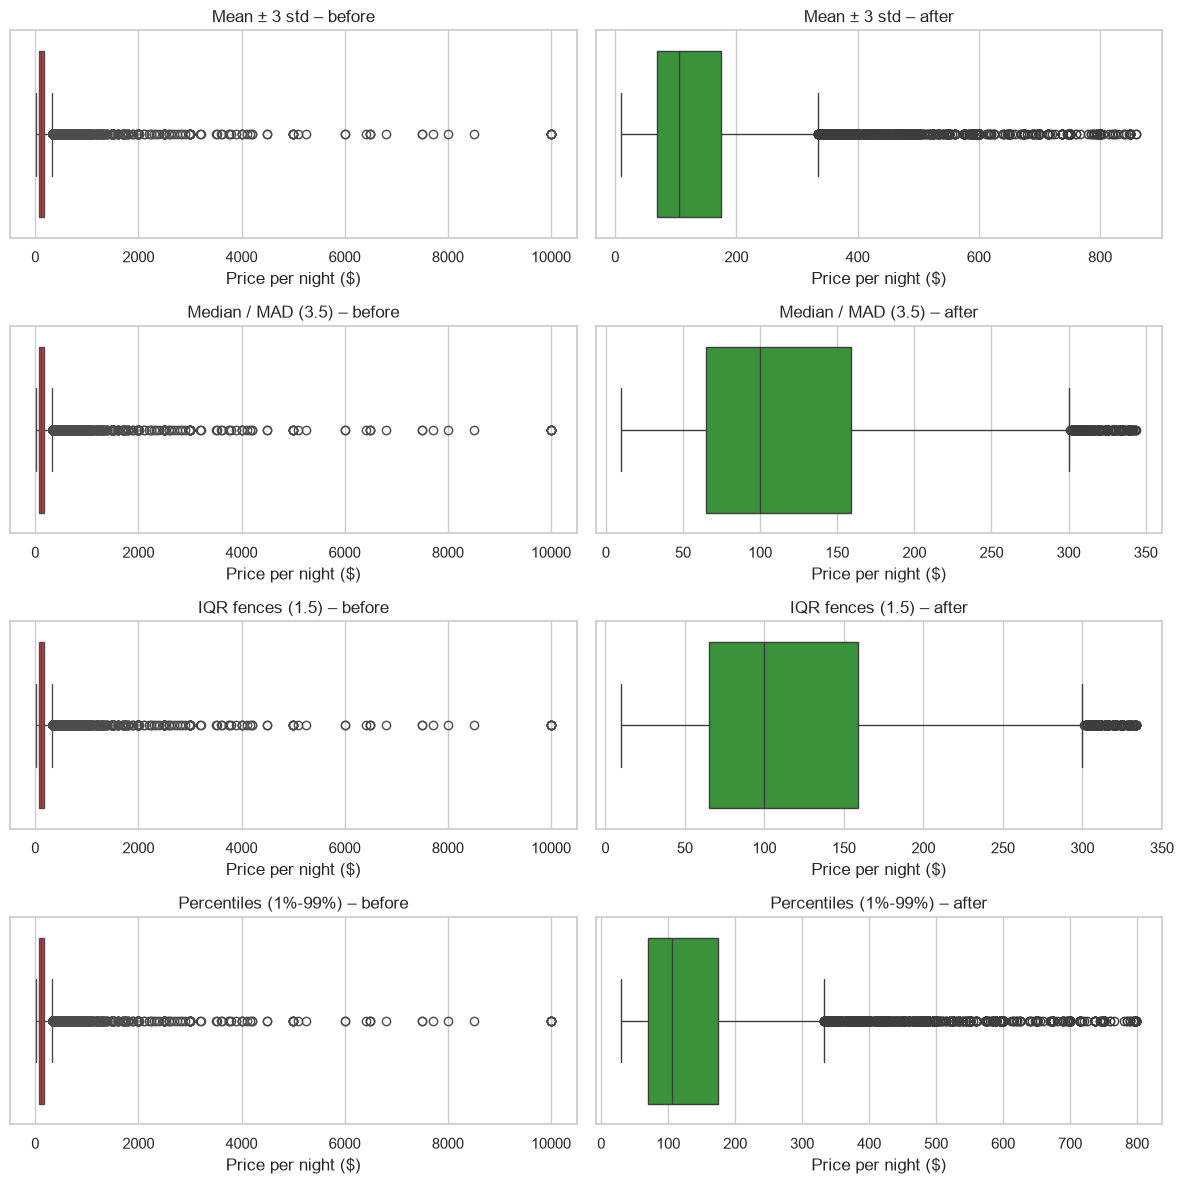

In [49]:
fig, axes = plt.subplots(len(methods), 2, figsize=(12, 3 * len(methods)))
for row, (name, (low, high, mask)) in zip(axes, methods.items()):
    sns.boxplot(x=price, ax=row[0], color="tab:red")
    row[0].set_title(f"{name} – before")
    sns.boxplot(x=price[mask], ax=row[1], color="tab:green")
    row[1].set_title(f"{name} – after")
    for ax in row:
        ax.set_xlabel("Price per night ($)")
plt.tight_layout()
plt.show()

**What I noticed:**

- **Mean ± 3 std:** This was the least useful for the extreme prices. The outliers make the standard deviation larger, so the limits are too wide (and the lower one is negative).
- **Median / MAD:** This removed about 6% of the listings, all from the expensive end. Its limits were also pretty close to the IQR limits.
- **IQR fences:** The result was similar to MAD. Both methods seem more useful here because a few extreme prices don't affect their limits as much.
- **Percentiles:** Easy to apply, but I'm not convinced a fixed 2% cut-off is always the best choice. It removes that share regardless of the shape of the data.

## B6. Final clean dataset

I went with the **IQR method** for the final cleaned dataset. It handles the extreme prices better than the mean-based approach, and unlike percentiles, it doesn't automatically remove a fixed percentage of listings. MAD gave a similar result, so that would also have been a reasonable option.

The cleaned data is stored in `airbnb_clean`. I didn't export it to a separate file, so I'd the notebook needs to be re-run to create it.

In [50]:
airbnb_clean = prices_df[mask_iqr].copy()
print("Original rows :", len(airbnb))
print("Clean rows    :", len(airbnb_clean))
print("Rows removed  :", len(airbnb) - len(airbnb_clean))
airbnb_clean["price"].describe().round(2)

Original rows : 48895
Clean rows    : 45912
Rows removed  : 2983


count    45912.00
mean       120.00
std         68.13
min         10.00
25%         65.00
50%        100.00
75%        159.00
max        334.00
Name: price, dtype: float64

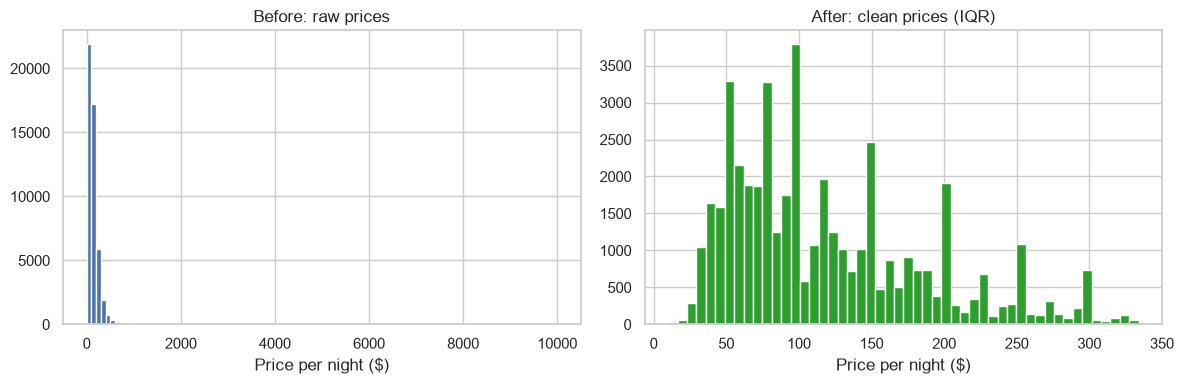

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(airbnb["price"], bins=100)
axes[0].set_title("Before: raw prices")
axes[1].hist(airbnb_clean["price"], bins=50, color="tab:green")
axes[1].set_title("After: clean prices (IQR)")
for ax in axes:
    ax.set_xlabel("Price per night ($)")
plt.tight_layout()
plt.show()

In [52]:
airbnb_clean.groupby("room_type")["price"].agg(["count", "mean", "median", "max"]).round(2)

,count,mean,median,max
room_type,,,,
Entire home/apt,22787,162.54,150.0,334
Private room,21989,79.04,70.0,333
Shared room,1136,59.40,45.0,320


After removing the $0 prices and the IQR outliers, the price distribution is much easier to read without the extreme values stretching the axis. We can see clearly the difference in the plots.